# Binary Classifiers

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2025-08-26.  
Copyright (c) 2020-2025, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

# <span style="color:red;background-color:yellow;">TODO</span>
1. clean out dead code
2. rename dataSetName = "shrunkBest200", "binaryClassifier training data" 
3. simulatedDataRootDir_G = "/private/groups/kimlab/aedavids/fagazi/simulatedData"
4. generate200lfcShrink.sh.out_best200_lfcShrink
5. src/bin/generate200lfcShrink.sh


In [1]:
defaultNotebookName="binaryClassifiers"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-11-20 11:29:04,431 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-11-20 11:29:04,432 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks]
2026-11-20 11:29:04,432 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/graceM/src/python/cliUtilities.py]
2026-11-20 11:29:04,433 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/graceM/src/jupyterNotebooks]


In [2]:
# use fitz to display pdf
# import fitz
import glob
from IPython.display import display
from IPython.display import HTML
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.axes import Axes
from matplotlib.patches import Patch

import numpy as np
import os
import pandas as pd
from pathlib import Path
import pprint as pp
import time
# local imports
from notebookUtils import appendToPYTHONPATH, getNotebookName

ORIG_PYTHONPATH = os.environ['PYTHONPATH']

extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2]) 

from archive.dataTypes import  ModelConfig
# from archive.saveDataTypes import archive 
from models.configMLWorkflow import configBinaryLoadAndSplit, configBinaryCalculateSensitivityAtSpecificity
from models.configMLWorkflow import configConfusionPanel, configEvaluate
from models.configMLWorkflow import configROCPanel, configVolcanoPanel
from models.mlWorkflow import trainRandomForest
# # from plots.sensitivity_at_specificity import computeSensitivitiesAtTargets
from plots.plotPanel import combineFigures, combineFiguresLayout, displayPDFInNotebook, getSubplotWidthAndHeight
from plots.plotPanel import Panel, setFigureFont
from plots.plotUtilities import saveDataFrameImage

notebook_start_time = time.time()
print("⏱️ Notebook started.")

2026-11-20 11:29:05,395 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA:/private/home/aedavids/extraCellularRNA/src]


⏱️ Notebook started.


/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [3]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'

notebookName: binaryClassifier
notebookDir: /private/home/aedavids/graceM/src/jupyterNotebooks


In [4]:
# _G : global use to insure we do not pick up globals in function by accident 
# durring refactoring

simulatedDataRootDir_G = "/private/groups/kimlab/aedavids/fagazi/simulatedData"

realDataRoot_G = "/private/groups/kimlab/data/elife"
realDataPath_G = f'{realDataRoot_G}/elife_all_norm_counts_2023-05-18.csv'
realMetaDataPath_G = f'{realDataRoot_G}/elife_scaled_metaData_2023-05-18.csv'

In [5]:
# shrunkDataSetConfig_G = ModelConfig(
#                         dataSetName = "shrunkBest20",
#                         rootOutDir = notebookOutDir,
#                         # simulatedDataPath = f"{simulatedDataRootDir_G}/generateSamplesBinaryShurnk.sh.out_bestShrunk20",
#                         simulatedDataPath = f"{simulatedDataRootDir_G}/generateSamplesBinaryShurnk.sh.out_best20_lfcShrink",
#                         realDataPath = realDataPath_G,
#                         realMetaDataPath = realMetaDataPath_G,
#                         deseqResultsType = 'results.lfcShrink',
#                     )

# # ran twice
# # first time is to get plot 
# # figure out what the abstract should be
# # run second time to store the abstract in the archive
# shrunkDataSetConfig_G.abstract = "For each of the 5 cancer types in the normalized elife data set, \nwe trained"\
#                         + " a random forest using the best 20 differential expressed cancer_type vs. healthy doner "


shrunk200DataSetConfig_G = ModelConfig(
                        dataSetName = "shrunkBest200",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{simulatedDataRootDir_G}/generate200lfcShrink.sh.out_best200_lfcShrink",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results.lfcShrink',
                    )
shrunk200DataSetConfig_G.abstract = "much better results when compared to shrunkBest20. areas needing improvement."\
    + "\n 1) colorectal TP = 79% healthy TP = 74. Esoph only has 23 features?. TODO explore feature importance. make sure we are not learning noise. "\
        + "\n check MI, check basemean"


# best200DataSetConfig_G = ModelConfig(
#                         dataSetName = "best200",
#                         rootOutDir = notebookOutDir,
#                         simulatedDataPath = f"{simulatedDataRootDir_G}/generate200.sh.out_best200_results",
#                         realDataPath = realDataPath_G,
#                         realMetaDataPath = realMetaDataPath_G,
#                         deseqResultsType = 'results',
#                     )
# best200DataSetConfig_G.abstract = "not much difference with shrunk200 data set"


# runConfig = shrunkDataSetConfig_G # debug version, runs fast 20 features
# runConfig = best200DataSetConfig_G
runConfig = shrunk200DataSetConfig_G # best sensitivity does slightly better 


## Train binary classifier

In [6]:
print(f'{runConfig.dataSetName}')
configBinaryLoadAndSplit( runConfig, diagnosis=["Colorectal", "Esophagus", "Liver", "Lung", "Stomach"] )

2026-11-20 11:29:07,204 WARNING configMLWorkflow.py configBinaryLoadAndSplit() line:104] [loading /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-11-20 11:29:07,205 WARNING configMLWorkflow.py configBinaryLoadAndSplit() line:105] [loading /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]
2026-11-20 11:29:07,206 WARNING configMLWorkflow.py configBinaryLoadAndSplit() line:106] [loading /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink]
2026-11-20 11:29:07,211 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Colorectal/formatSynthetics.py.out/X.csv]


shrunkBest200


2026-11-20 11:29:08,165 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Colorectal/formatSynthetics.py.out/y.csv]
2026-11-20 11:29:08,518 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-11-20 11:29:09,798 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]
2026-11-20 11:29:09,859 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Esophagus/formatSynthetics.py.out/X.csv]
2026-11-20 11:29:09,892 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/aedavids/fagazi/simulatedData/generate200lfcShrink.sh.out_best200_lfcShrink/Esophagus/formatSynthetics.py.out/y.csv]
2026-11-20 11:29:09,

In [7]:
# # add the path to the DESeqResults
# # if runConfig.deseqResultsRootPath:
# # this will not work for multiclassifiers
# for key, db in runConfig.dataDict.items():
#     drType = runConfig.deseqResultsType
#     print(f'key : {key} drType : {drType}')    
#     tList = glob.glob( f'{runConfig.simulatedDataPath}/{key}/*/*.{drType}' )
#     print(f't : \n{tList[0]}')
    
#     # only generate volcano plot on the trained model bundle.
#     # all the other mb's will have the same features
#     db.simTrain.deseqResultsPath = tList[0]

In [8]:
trainRandomForest( runConfig.dataDict, n_estimators=1000 )

2026-11-20 11:29:17,739 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (7999, 200) y.shape : (7999,)]


Colorectal


2026-11-20 11:29:43,586 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (879, 22) y.shape : (879,)]


Esophagus


2026-11-20 11:29:46,028 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (7999, 200) y.shape : (7999,)]


Liver


2026-11-20 11:30:07,256 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (6000, 150) y.shape : (6000,)]


Lung


2026-11-20 11:30:29,301 WARNING mlWorkflow.py trainRandomForest() line:430] [XDF.shape : (7999, 200) y.shape : (7999,)]


Stomach


## Evaluate binary classifiers

In [9]:
configEvaluate( runConfig )

diganosis : Colorectal dataSet : simTrain


2026-11-20 11:30:56,444 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Colorectal_Cancer-simTrain.png]
2026-11-20 11:30:57,314 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Colorectal_Cancer-simTrain.pdf]
2026-11-20 11:30:58,621 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Colorectal_Cancer-simTrain.png]
2026-11-20 11:30:58,717 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Colorectal_Cancer-simTrain.pdf]


diganosis : Esophagus dataSet : simTrain


2026-11-20 11:30:59,782 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Esophagus_Cancer-simTrain.png]
2026-11-20 11:31:00,496 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Esophagus_Cancer-simTrain.pdf]
2026-11-20 11:31:01,350 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Esophagus_Cancer-simTrain.png]
2026-11-20 11:31:01,444 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Esophagus_Cancer-simTrain.pdf]


diganosis : Liver dataSet : simTrain


2026-11-20 11:31:02,801 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Liver_Cancer-simTrain.png]
2026-11-20 11:31:03,520 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Liver_Cancer-simTrain.pdf]
2026-11-20 11:31:04,711 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Liver_Cancer-simTrain.png]
2026-11-20 11:31:04,806 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Liver_Cancer-simTrain.pdf]


... (30 outputs left out)

diganosis : Lung dataSet : real


2026-11-20 11:31:49,886 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Lung_Cancer-real.png]
2026-11-20 11:31:50,597 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Lung_Cancer-real.pdf]
2026-11-20 11:31:51,431 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Lung_Cancer-real.png]
2026-11-20 11:31:51,525 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Lung_Cancer-real.pdf]


diganosis : Stomach dataSet : real


2026-11-20 11:31:52,519 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Stomach_Cancer-real.png]
2026-11-20 11:31:53,229 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/confusionMatrix_Stomach_Cancer-real.pdf]
2026-11-20 11:31:54,053 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Stomach_Cancer-real.png]
2026-11-20 11:31:54,148 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/roc_Stomach_Cancer-real.pdf]


In [10]:
# configConfusionPanel( runConfig, "simTrain" )

In [11]:
# configConfusionPanel( runConfig, "simVal" )

# Evaluate Models train on simulated data using Real hold out examples

In [12]:
# configConfusionPanel( runConfig, "real" )

In [13]:
# logger.warning("AEDWIP TODO REFACTOR")

# def displaySensitivityAndSpecificity() -> pd.DataFrame:
#     sensitivities = []
#     specificities = [] 
#     indicies = []
#     controlClass = "Healthy_donor"
#     for key, db in runConfig.dataDict.items():
#         realModel = db.real 
#         sDict = realModel.statsDict
#         for kclass, statsDict in sDict.items():
#             if kclass == controlClass:
#                 continue
#             indicies.append(kclass)
#             sensitivities.append(statsDict['sensitivity'] )
#             specificities.append(statsDict['specificity'])

#     retDF =  pd.DataFrame( data={
#                                 "sensitivity" : sensitivities,
#                                 "specificity" : specificities
#                                 },
#                             index=indicies ).round(2)
    
#     return retDF


# sensAndSpecDF = displaySensitivityAndSpecificity()
# print(f'{runConfig.dataSetName} real Data Set Sensitivity (True Positive Rate) and Specificity (True Negative Rate)')
# display( sensAndSpecDF )

# sensAndSpecDFImgPath = f'{runConfig.imgOutDir}/realSensAndSpecDF.png'
# saveDataFrameImage(sensAndSpecDF, sensAndSpecDFImgPath)

In [14]:
# configROCPanel( runConfig, "real" )

In [15]:
# configVolcanoPanel( runConfig )

In [16]:
# def aedwipUpsetPlot(config : ModelConfig):
#     ''' 
#     TODO
#     '''
#     searchPath = f'{config.simulatedDataPath}/*/*/*.{config.deseqResultsType}' 
#     print(searchPath)
#     resultsFiles = glob.glob(searchPath)
#     # for i in range(len(resultsFiles)):
#     #     print(resultsFiles[i])
    
#     resultsDict = dict()
    
#     for rPath in resultsFiles:
#         # fileName = Lung_vs_Healthy_donor.results.lfcShrink
#         fileName = rPath.split("/")[-1]
        
#         # key = Lung_vs_Healthy_donor
#         key = fileName.split(".")[0]
#         #print(f'{fileName} {key}')
#         # df = pd.read_csv(rPath)
#         # print(df.head())
        
#         from selectFeatures.driver import _countExtraHeaderLines
#         numRowsToSkip = _countExtraHeaderLines(rPath)
#         #print(f'\n{key} {numRowsToSkip}')
#         deseqDF = pd.read_csv(rPath, skiprows=numRowsToSkip)
#         #print(f'{deseqDF.shape}')
        
#         resultsDict[key] = deseqDF


#     from plots.upsetPlotDataFactory import UpsetPlotDataFactory
#     upsetFactory = UpsetPlotDataFactory()
    
#     t = upsetFactory.createUpsetPlotDataFromSetDict(resultsDict)
#     upsetPlotDataDF, geneSetsDict = t
    
#     from selectFeatures.signatureGeneConfig import SignatureGeneConfiguration
#     title = f"{config.dataSetName} {config.deseqResultsType}"
#     sgc = SignatureGeneConfiguration(
#                  dataSetName=config.dataSetName, 
#                  design=None, 
#                  padjThreshold=None, 
#                  lfcThreshold=None, 
#                  n=None, 
#                  localCacheRootPath=None, 
#                  title=title
#     )
    
#     from plots.upsetPlots import UpsetPlot
#     upsetPlot = UpsetPlot(signatureGeneConfig=sgc, 
#                           geneSetsDict=geneSetsDict, 
#                           geneSetsUpsetPlotData=upsetPlotDataDF
#                           )
    
#     # full plot, all sets and intersections
#     fig, pltDict = upsetPlot.configurablePlot(show_counts=True)
#     # plt.suptitle("aEDWIP suptitle")
    
#     #
#     # find all the intersections
#     #
#     intersectionDict = upsetPlot.findIntersectionElements()  
    
#     return(fig, pltDict, intersectionDict)


# fig, pltDict, intersectionDict = aedwipUpsetPlot(runConfig)


In [17]:
# logger.error(f'AEDWIP save upset plot')
# logger.error(f'AEDWIP save interesection dict')
# logger.error(pp.pformat(intersectionDict))

# Calculate Sensitivity @ Specificity

In [18]:
def calculateSensitivityAtSpecificty(
        config : ModelConfig
    ) -> pd.DataFrame:
    """ 
    TODO
    
    similar to multiclass version
    
    returns senitivityAtSpecificityDF
    """ 
    specificityTarget=0.9
    senitivityAtSpecificityDF = configBinaryCalculateSensitivityAtSpecificity(config,
                                                        specifityTargets = [specificityTarget]
                                                        )
    savePath = f'{config.outDirPath}/{config.dataSetName}_SensAtSpec.csv'
    senitivityAtSpecificityDF.to_csv(savePath, index=False)
    config.resultsDict['senitivityAtSpecificity'] = savePath
    logger.warning(f'saving : {savePath}')
    
    return senitivityAtSpecificityDF
    
print(f'\ndataSet {runConfig.dataSetName}')
ssDF = calculateSensitivityAtSpecificty(runConfig)
display( ssDF )

# sensAndSpecDFImgPath = f'{runConfig.imgOutDir}/realSens@0.9SpecDF.png'
# saveDataFrameImage(ssDF, sensAndSpecDFImgPath)


dataSet shrunkBest200


2026-11-20 11:31:54,834 WARNING 1335613866.py calculateSensitivityAtSpecificty() line:18] [saving : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/shrunkBest200_SensAtSpec.csv]


,diagnosis,Target Specificity,Sensitivity (TPR),Achieved Specificity (TNR),Approx. Threshold,auc,nSimTrainSamples,nSimTrainFeatures,nRealTestSamples,nRealTestFeatures
0,Colorectal,0.9,0.924528,0.9,0.357,0.959193,7999,200,96,200
1,Esophagus,0.9,0.424194,0.9,1.000,0.854839,879,22,74,22
2,Liver,0.9,0.923077,0.9,0.210,0.974955,7999,200,69,200
3,Lung,0.9,0.942857,0.9,0.792,0.982392,6000,150,78,150
4,Stomach,0.9,0.722222,0.9,0.827,0.936047,7999,200,79,200


In [19]:
# print(ssDF.to_markdown(index=True))


In [20]:
# archive(runConfig)

### <span style="color:red;background-color:yellow;">9/8/26 modified ROC AUC plots to show sensitivity as specificity for manuscript</span>

diganosis : Colorectal dataSet : real


2026-11-20 11:31:55,254 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Colorectal-cancer-real.png]
2026-11-20 11:31:55,365 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Colorectal-cancer-real.pdf]


diganosis : Esophagus dataSet : real


2026-11-20 11:31:55,735 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Esophagus-cancer-real.png]
2026-11-20 11:31:55,830 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Esophagus-cancer-real.pdf]


diganosis : Liver dataSet : real


2026-11-20 11:31:56,177 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Liver-cancer-real.png]
2026-11-20 11:31:56,269 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Liver-cancer-real.pdf]


diganosis : Lung dataSet : real


2026-11-20 11:31:56,616 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Lung-cancer-real.png]
2026-11-20 11:31:56,709 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Lung-cancer-real.pdf]


diganosis : Stomach dataSet : real


2026-11-20 11:31:57,055 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Stomach-cancer-real.png]
2026-11-20 11:31:57,150 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/rocSensitivityAtSpecificity_Stomach-cancer-real.pdf]


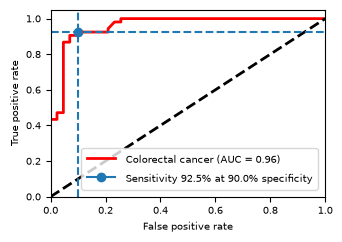

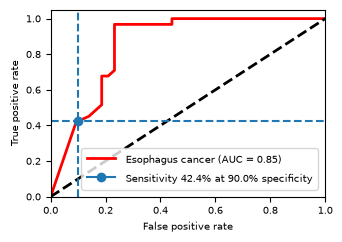

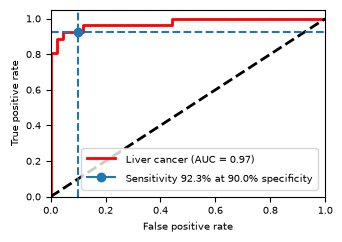

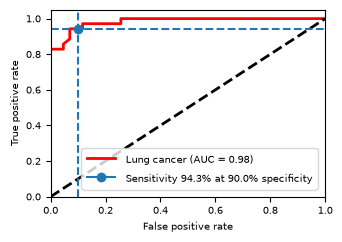

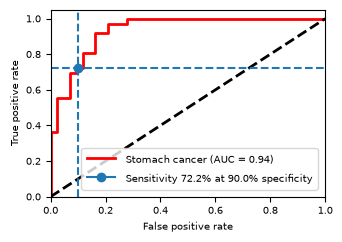

In [21]:
from archive.archiveUtilities import saveFigure
from plots.plotROCCurve import plotROCCurve
from utilities import isOrderedCategoricalSeries

# ref :
# configMLWorkflow configEvaluate()
# mlWorkflow evaluate ()
# debugSensitivity = 0.924528 
# debugSpecificityAt = 0.9


def plotROCManuscript(
        panelWidthInMM : int,
        panelHeightInMM : int,
        fontSize : int = 7, 
    ) -> list[plt.figure]:
    '''
    create an ROC-AUC plot for each diagnosis with a lines showing
    sensitivity @ 90% specificity on the ROC plot
    
    assumes the plots will be assembled into a 2 x 3 panel
    
    fontSize default 7pt is nature bio medical engineerings max size. min is 5pt
   
        
    '''
    plotSSDF = ssDF.set_index("diagnosis")

    # assume 2 columns.
    widthInInches = (panelWidthInMM / 2) / 25.4
    
    # assume three rows
    heightInInches = (panelHeightInMM / 3) / 25.4
    
    retListofFigs = []
    for  dataSet in [ "real"]:
            for diganosis, diagnosticBundle in runConfig.dataDict.items():
                print(f'diganosis : {diganosis} dataSet : {dataSet}')
                #evaluate(diagnosticBundle, dataSet=dataSet, outDirArg=config.imgOutDir)
                
                modelBundle = getattr(diagnosticBundle, dataSet)

                XDF = modelBundle.X
                model = modelBundle.model
                
                # ySeries value type is an ordered pd.Categorical 
                ySeries = modelBundle.y
                if not isOrderedCategoricalSeries(ySeries):
                    errMsg = f'argument ySeries {type(ySeries)} expected pandas series with an ordered categorical dtype'
                    logger.error(errMsg)
                    raise TypeError(errMsg)
                    
                # we need the title to save the file
                # do not pass a title to the plot function.
                # we are going to create a single panel.
                # we want the panel to be as small and tight as possible
                #
                # 'Stomach_Cancer' ->  'Stomach cancer' text.replace("_C", " c")
                diagnosis = diagnosticBundle.diagnosis.replace("_C", " c")
                title = f'{diagnosis} {dataSet}'
                fig, ax, aucDict = plotROCCurve(
                    model=model,
                    XDF=XDF ,
                    ySeries=ySeries,
                    figsize=(widthInInches, heightInInches),
                    title=None, # title,
                    )
                
                retListofFigs.append(fig)
                
                sensitivity, specificity = plotSSDF.loc[ diganosis , ['Sensitivity (TPR)', 'Achieved Specificity (TNR)']]
                
                # add sensitivity@specifity
                # fpr = 1.0 - debugSpecificityAt
                fpr = 1.0 - specificity
                
                ax.axvline(
                    x=fpr,
                    linestyle='--',
                )

                ax.axhline(
                    # y=debugSensitivity,
                    y=sensitivity,
                    linestyle='--',
                )
                
                ax.plot(
                    fpr,
                    # debugSensitivity,
                    sensitivity,
                    marker='o',
                    # label=f'Sensitivity {debugSensitivity:.1%} @ {debugSpecificityAt:.1%} Specificity'
                    # label=f'Sensitivity {sensitivity:.1%} @ {specificity:.1%} Specificity'
                    label=f'Sensitivity {sensitivity:.1%} at {specificity:.1%} specificity'
                )
                
                # we need to rebuild the legend before we make changes
                ax.legend()

                # change the font sizes, 
                # when we shrink the plots to create a panel the fonts are to small
                ax.tick_params(axis='both', labelsize=fontSize)
                ax.xaxis.label.set_size(fontSize)
                ax.yaxis.label.set_size(fontSize)
                ax.title.set_fontsize(fontSize)
                
                # fix capitalization
                # False Positive Rate -> False positive rate
                originalXAxisLabel = ax.get_xlabel()
                ax.set_xlabel(originalXAxisLabel.lower().capitalize())
                
                # True Positive Rate -> True positive rate
                originalYAxisLabel = ax.get_ylabel()
                ax.set_ylabel(originalYAxisLabel.lower().capitalize())

                legend = ax.get_legend()
                if legend is not None:
                    for text in legend.get_texts():
                        text.set_fontsize(fontSize) 
                        # fix capitalization
                        originalText = text.get_text()
                        if 'Cancer' in originalText:
                            newText = (
                                originalText
                                .replace("_", " ")
                                .replace("Cancer", "cancer")
                            )
                            text.set_text(newText)

                    legend.get_title().set_fontsize(fontSize)                       
                
                prefix = "rocSensitivityAtSpecificity"
                outDirArg=runConfig.imgOutDir
                rocPlotPath = saveFigure(fig,  title, outDirArg, prefix)
                # resultsDict['rocFig'] = rocPlotPath
    
    return retListofFigs

rocManuscriptFigs : list[plt.figure] = plotROCManuscript(
    panelWidthInMM=180,
    panelHeightInMM=185,
)

# <span style="color:red;background-color:yellow;">10/2/26 create final artwork</span>
panel width = 180 mm == 7.09 inches
panel height = 185 mm == 7.28 inches

figsize = (180/25.4, 185/25.4)

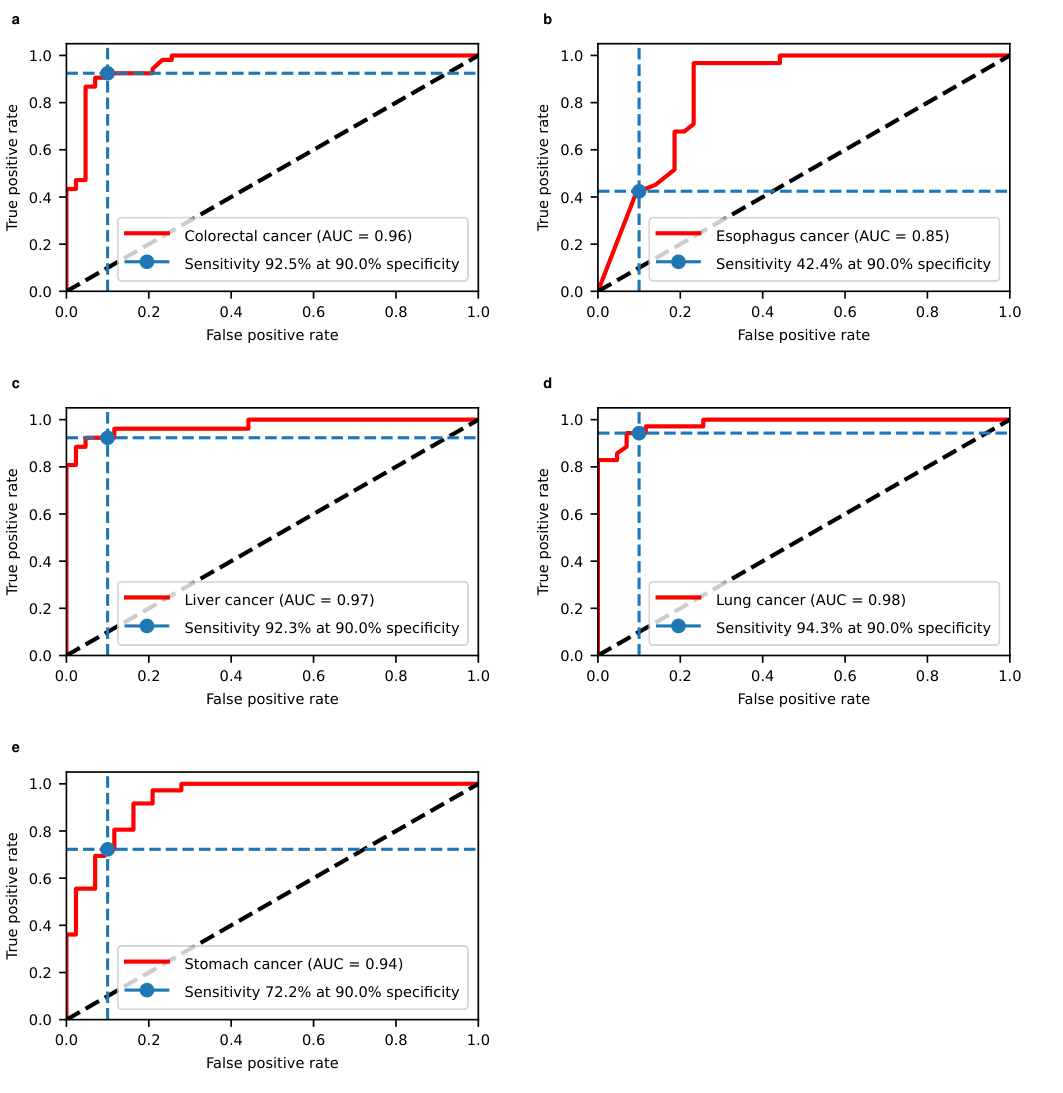

PosixPath('/private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/panel/manuscript/rocSensitivityAt90Specificity.pdf')

In [22]:

rocManuscriptOutputStem = f'{runConfig.imgPanelOutDir}/manuscript/rocSensitivityAt90Specificity'
rocManuscriptPdfPath, rocManuscriptPngPath = combineFigures(
                rocManuscriptFigs,
                rocManuscriptOutputStem,
                bottomMargin=0.20
                )

displayPDFInNotebook(rocManuscriptPdfPath)
rocManuscriptPdfPath

In [23]:
fooDF = ssDF.set_index("diagnosis")
print(fooDF.columns)
fooDF

Index(['Target Specificity', 'Sensitivity (TPR)', 'Achieved Specificity (TNR)',
       'Approx. Threshold', 'auc', 'nSimTrainSamples', 'nSimTrainFeatures',
       'nRealTestSamples', 'nRealTestFeatures'],
      dtype='str')


,Target Specificity,Sensitivity (TPR),Achieved Specificity (TNR),Approx. Threshold,auc,nSimTrainSamples,nSimTrainFeatures,nRealTestSamples,nRealTestFeatures
diagnosis,,,,,,,,,
Colorectal,0.9,0.924528,0.9,0.357,0.959193,7999,200,96,200
Esophagus,0.9,0.424194,0.9,1.000,0.854839,879,22,74,22
Liver,0.9,0.923077,0.9,0.210,0.974955,7999,200,69,200
Lung,0.9,0.942857,0.9,0.792,0.982392,6000,150,78,150
Stomach,0.9,0.722222,0.9,0.827,0.936047,7999,200,79,200


## <span style="color:red;background-color:yellow;">10/20/22 create Extended Data Figure F_R3_1 Binary classifier performance on independent real samples: simulated training vs. Reggiardo et al. final artwork</span>

values copied from 
1. Reggiardo, R. E. et al. Profiling of repetitive RNA sequences in the blood plasma of patients with cancer. Nat. Biomed. Eng 1–9 (2023) doi:10.1038/s41551-023-01081-7.


In [24]:
comparisonDF = pd.DataFrame(
    [
        # Diagnosis    Source                 AUC   Sensitivity  Training  Test  Features
        ("Colorectal", "Simulated training",   0.96, 0.92,        7999,     97,   200),
        ("Colorectal", "Reggiardo et al.",     0.95, 0.70,          79,     18,   109),

        ("Esophagus", "Simulated training",    0.85, 0.42,         879,     74,    22),
        ("Esophagus", "Reggiardo et al.",      0.87, 0.83,          61,     14,    19),

        ("Liver", "Simulated training",        0.97, 0.92,        7999,     70,   200),
        ("Liver", "Reggiardo et al.",          0.94, 0.80,          57,     13,   201),

        ("Lung", "Simulated training",         0.98, 0.94,        6000,     79,   150),
        ("Lung", "Reggiardo et al.",           0.94, 0.71,          64,     15,  2118),

        ("Stomach", "Simulated training",      0.93, 0.72,        7999,     79,   200),
        ("Stomach", "Reggiardo et al.",        0.96, 1.00,          64,     15,   118),
    ],
    columns=[
        "diagnosis",
        "source",
        "auc",
        "sensitivity",
        "trainingSamples",
        "testSamples",
        "features",
    ],
)

In [25]:
def plotBinaryComparisonFinalArtwork(
    df: pd.DataFrame,
    column: str,
    fontSize: float = 7,
    *, # * means all arguments after it must be passed by name.
    widthInMM: float = 85,
    heightInMM: float = 65,
    showLegend: bool = False,
    tickFontSize: float = 6,
    barLabelFontSize: float = 6,
    ) -> tuple[Figure, Axes]:
    """
    Create one grouped bar-chart panel comparing the two sources.
    """

    # ylabel, logarithmic scale, limits
    settings = {
        "auc": (
            # "AUC", False, (0, 1.10)
            "AUC", False, (0, 1.15)
        ),
        "sensitivity": (
            "Sensitivity at 90% specificity", False, (0, 1.10)
        ),
        "trainingSamples": (
            "Training samples", True, (10, 100_000)
        ),
        "testSamples": (
            "Test samples", False, (0, 120)
        ),
        "features": (
            "Features", True, (10, 10_000)
        ),
    }

    if column not in settings:
        raise ValueError(f"column must be one of {list(settings)}")

    sources = ["Simulated training", "Reggiardo et al."]
    colors = ["#40358C", "#168580"]

    # Preserve diagnosis order from the input DataFrame.
    diagnoses = df["diagnosis"].drop_duplicates().tolist()
    values = (
        df.pivot(index="diagnosis", columns="source", values=column)
        .reindex(index=diagnoses, columns=sources)
    )

    if values.isna().any().any():
        raise ValueError("Each diagnosis must have a value for both sources.")

    ylabel, logScale, limits = settings[column]
    isScore = column in {"auc", "sensitivity"}

    style = {
        "font.family": "Arial",
        "font.size": fontSize,
        "font.weight": "normal",
        "axes.labelsize": fontSize,
        "axes.labelweight": "normal",
        "axes.titlesize": fontSize,
        # "xtick.labelsize": fontSize,
        # "ytick.labelsize": fontSize,
        "xtick.labelsize": tickFontSize,
        "ytick.labelsize": tickFontSize,
        "legend.fontsize": fontSize,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }

    with mpl.rc_context(style):
        fig, ax = plt.subplots(
            figsize=(widthInMM / 25.4, heightInMM / 25.4),
            layout="constrained",
        )

        x = np.arange(len(diagnoses))
        # barWidth = 0.36
        barWidth = 0.32
        barSeparation = 0.46  # Distance between the two bar centers

        for i, (source, color) in enumerate(zip(sources, colors)):
            y = values[source].to_numpy()

            bars = ax.bar(
                # x + (i - 0.5) * barWidth,
                x + (i - 0.5) * barSeparation,
                y,
                width=barWidth,
                color=color,
                label=source,
                linewidth=0,
                zorder=3,
            )

            labels = [
                f"{value:.2f}" if isScore else f"{value:,.0f}"
                for value in y
            ]
            # ax.bar_label(
            #     bars,
            #     labels=labels,
            #     padding=2,
            #     fontsize=fontSize,
            #     fontweight="normal",
            # )
            
            # Stagger labels in panels where paired values are close together.
            # This separates labels such as 0.96 / 0.95 and 200 / 201 vertically.
            labelPadding = 2
            # if column in {"auc", "features"} and i == 1:
            #     labelPadding += barLabelFontSize + 1

            ax.bar_label(
                bars,
                labels=labels,
                padding=labelPadding,
                fontsize=barLabelFontSize,
                fontweight="normal",
                zorder=10,  # Keep every label above both series of bars
            )

        ax.set_xticks(x)
        ax.set_xticklabels(diagnoses, rotation=35, ha="right")
        ax.set_xlabel('Cancer diagnosis')
        
        if column == "sensitivity":
            ax.set_ylabel("Sensitivity at\n90% specificity")
        else:
            ax.set_ylabel(ylabel)
        # ax.set_ylabel(ylabel)

        if logScale:
            ax.set_yscale("log")
            ax.minorticks_off()
        elif isScore:
            ax.set_yticks(np.arange(0, 1.01, 0.2))

        ax.set_ylim(*limits)
        ax.set_axisbelow(True)
        ax.grid(axis="y", linestyle="--", linewidth=0.4, alpha=0.35)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(axis="x", length=0)

        if showLegend:
            ax.legend(
                loc="upper center",
                bbox_to_anchor=(0.5, -0.32),
                ncol=2,
                frameon=False,
            )

    # fig.tight_layout()
    return fig, ax

In [26]:
figureWidthMM = 180
panelAreaHeightMM = 102
legendHeightMM = 8

panelWidthMM = 58
panelHeightMM = 48

binaryComparisonLayout: dict[str, Panel] = {
    "a": Panel(
        label="a",
        leftMm=1, topMm=2,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "b": Panel(
        label="b",
        leftMm=61, topMm=2,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "c": Panel(
        label="c",
        leftMm=121, topMm=2,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "d": Panel(
        label="d",
        leftMm=31, topMm=52,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
    "e": Panel(
        label="e",
        leftMm=91, topMm=52,
        widthMm=panelWidthMM, heightMm=panelHeightMM,
    ),
}

layout[a].widthMm : 58
layout[a].heightMm : 48
layout[b].widthMm : 58
layout[b].heightMm : 48
layout[c].widthMm : 58
layout[c].heightMm : 48


2026-11-20 11:32:00,175 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,181 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,182 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,183 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,184 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,185 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,186 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,187 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


layout[d].widthMm : 58
layout[d].heightMm : 48
layout[e].widthMm : 58
layout[e].heightMm : 48


2026-11-20 11:32:00,209 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,210 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,211 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,212 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,213 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,214 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,214 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:00,217 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


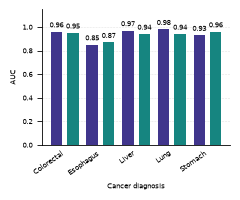

2026-11-20 11:32:01,827 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:01,828 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:01,829 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:01,830 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:01,831 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:01,832 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:01,833 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:01,834 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


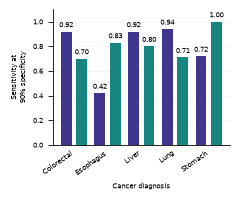

2026-11-20 11:32:02,237 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,239 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,240 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,241 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,244 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,246 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,247 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,248 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


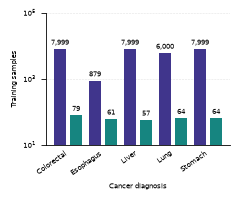

2026-11-20 11:32:02,628 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,629 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,630 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,631 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,632 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,634 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,635 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,636 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


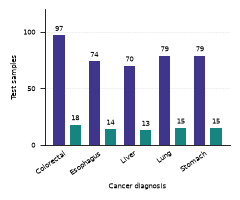

2026-11-20 11:32:02,957 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,958 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,959 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,960 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,961 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,963 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,965 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:02,967 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


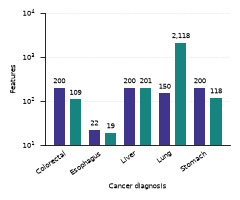

In [27]:
def runFinalArtwork(
                    layout: dict[str, Panel], 
                    fontSize : int = 7
                    ) -> None :
    ''' 
    TODO 
    '''
    panelIdColDict = {
        "a" : "auc", 
        "b" : "sensitivity", 
        "c" : "trainingSamples", 
        "d" : "testSamples", 
        "e" : "features", 
    }
    
    for panelId, col in panelIdColDict.items() : 
        widthMM, heightMm = getSubplotWidthAndHeight(layout, panelId)
        fig, ax = plotBinaryComparisonFinalArtwork(
                                    df=comparisonDF,
                                    column=col,
                                    fontSize=fontSize,
                                    widthInMM=widthMM,
                                    heightInMM=heightMm,
                                    showLegend= False,
                                    tickFontSize=fontSize,
                                    barLabelFontSize=fontSize,
                                    )
        layout[panelId].figure = fig
        
        
runFinalArtwork(binaryComparisonLayout, fontSize=5)


In [28]:
def plotBinaryComparisonLegend(
    widthInMM: float = 180,
    heightInMM: float = 12,
    fontSize: float = 7,
):
    """
    Create a standalone shared legend for the comparison panels.
    """

    fig, ax = plt.subplots(
        figsize=(widthInMM / 25.4, heightInMM / 25.4),
    )
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    ax.set_axis_off()

    handles = [
        Patch(
            facecolor="#40358C",
            edgecolor="none",
            label="Simulated training",
        ),
        Patch(
            facecolor="#168580",
            edgecolor="none",
            label="Reggiardo et al.",
        ),
    ]

    ax.legend(
        handles=handles,
        loc="center",
        ncol=2,
        frameon=False,
        prop={
            "family": "Arial",
            "size": fontSize,
            "weight": "normal",
        },
        handlelength=1.5,
        handletextpad=0.6,
        columnspacing=2,
    )

    return fig, ax

2026-11-20 11:32:03,373 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,374 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,375 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,377 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,378 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,379 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,380 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,380 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


Layout valid: 180 × 118 mm total; panels occupy extents of 179 × 100 mm.


2026-11-20 11:32:03,572 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,579 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,581 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,582 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,584 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,586 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,587 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:03,588 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


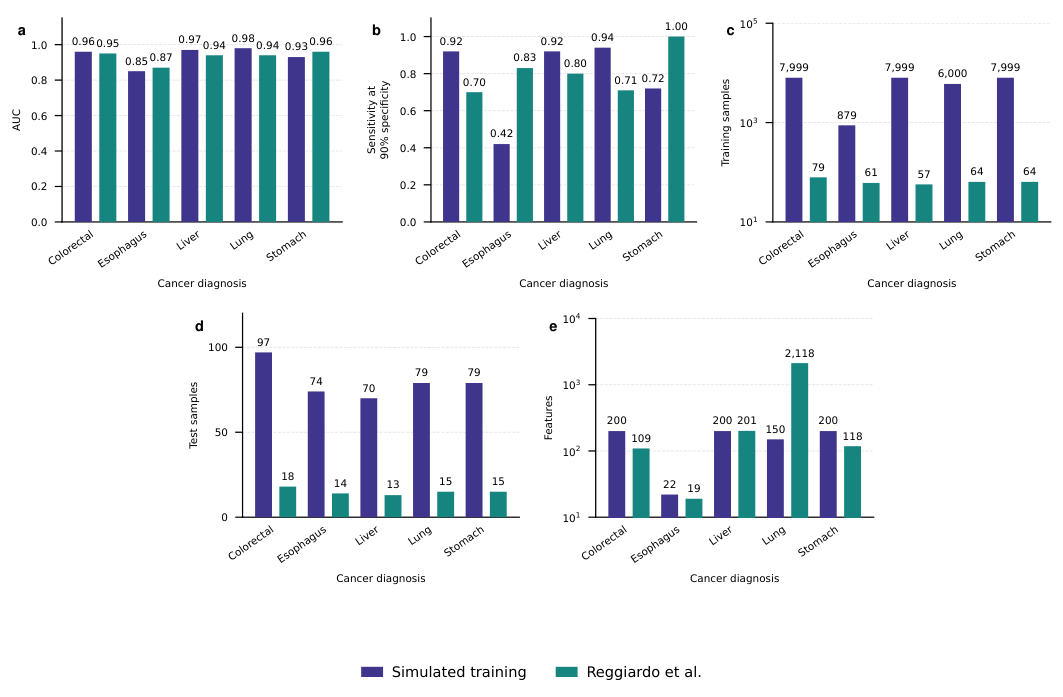

2026-11-20 11:32:06,247 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:06,248 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:06,249 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:06,251 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:06,251 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:06,253 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:06,254 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-20 11:32:06,255 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


saved : /private/home/aedavids/graceM/src/jupyterNotebooks/binaryClassifier.out/shrunkBest200/img/panel/manuscript/Exd_F_R3_1_binaryComparison.pdf


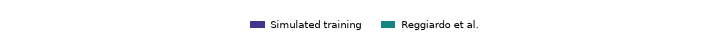

In [29]:
legendFig, legendAx = plotBinaryComparisonLegend(
    widthInMM=figureWidthMM,
    heightInMM=legendHeightMM,
    fontSize=7,
)

outputStem = Path(
    f"{runConfig.imgPanelOutDir}/manuscript/Exd_F_R3_1_binaryComparison"
)
outputStem.parent.mkdir(parents=True, exist_ok=True)

pdfPath, pngPath = combineFiguresLayout(
    panels=binaryComparisonLayout,
    outputStem=outputStem,
    widthMm=figureWidthMM,
    heightMm=panelAreaHeightMM + legendHeightMM,
    legendHeightMm=legendHeightMM,
    legendFigure=legendFig,
)

displayPDFInNotebook(pdfPath)
print(f'saved : {pdfPath}')

In [30]:
logger.warning("END NOTEBOOK")
elapsed = time.time() - notebook_start_time
hours, rem = divmod(elapsed, 3600)
minutes, seconds = divmod(rem, 60)
print(f"✅ Notebook completed in {int(hours)}h {int(minutes)}m {seconds:.1f}s.")

2026-11-20 11:32:06,331 WARNING 2279843384.py <module>() line:1] [END NOTEBOOK]


✅ Notebook completed in 0h 2m 59.2s.
